In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
cardio_df = pd.read_csv('cardio_data.csv')
cardio_df.head()

,id,Age,Gender,Height,Weight,Systolic,Diastolic,Cholesterol,Glucose,Smoke,Alcohol,Physical_Activity,CVD
0,0,18393,2,168,62.0,110,80,normal,normal,0,no,yes,0
1,1,20228,1,156,85.0,140,90,very high,normal,0,no,yes,1
2,2,18857,1,165,64.0,130,70,very high,normal,0,no,no,1
3,3,17623,2,169,82.0,150,100,normal,normal,0,no,yes,1
4,4,17474,1,156,56.0,100,60,normal,normal,0,no,no,0


In [3]:
#match the column names and codes used in the original Excel file
dt = cardio_df.copy()

dt = dt.rename(columns={'Age': 'age', 'Gender': 'gender', 'Height': 'height', 'Weight': 'weight',
                        'Systolic': 'systolic_bp', 'Diastolic': 'diastolic_bp',
                        'Cholesterol': 'cholesterol', 'Glucose': 'gluc', 'Smoke': 'smoke',
                        'Alcohol': 'alco', 'Physical_Activity': 'active', 'CVD': 'cardio'})

levels = {'normal': 1, 'high': 2, 'very high': 3}
dt['cholesterol'] = dt['cholesterol'].map(levels)
dt['gluc'] = dt['gluc'].map(levels)
dt['alco'] = dt['alco'].map({'no': 0, 'yes': 1})
dt['active'] = dt['active'].map({'no': 0, 'yes': 1})

#gender: 1 = women becomes 0, 2 = men becomes 1
dt['gender'] = np.where(dt['gender'] == 1, 0, 1)
dt.head()

,id,age,gender,height,weight,systolic_bp,diastolic_bp,cholesterol,gluc,smoke,alco,active,cardio
0,0,18393,1,168,62.0,110,80,1,1,0,0,1,0
1,1,20228,0,156,85.0,140,90,3,1,0,0,1,1
2,2,18857,0,165,64.0,130,70,3,1,0,0,0,1
3,3,17623,1,169,82.0,150,100,1,1,0,0,1,1
4,4,17474,0,156,56.0,100,60,1,1,0,0,0,0


In [4]:
dt['age_year'] = np.round(dt['age'] / 365)
dt.head()

,id,age,gender,height,weight,systolic_bp,diastolic_bp,cholesterol,gluc,smoke,alco,active,cardio,age_year
0,0,18393,1,168,62.0,110,80,1,1,0,0,1,0,50.0
1,1,20228,0,156,85.0,140,90,3,1,0,0,1,1,55.0
2,2,18857,0,165,64.0,130,70,3,1,0,0,0,1,52.0
3,3,17623,1,169,82.0,150,100,1,1,0,0,1,1,48.0
4,4,17474,0,156,56.0,100,60,1,1,0,0,0,0,48.0


In [5]:
dt.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 70000 entries, 0 to 69999
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   id            70000 non-null  int64  
 1   age           70000 non-null  int64  
 2   gender        70000 non-null  int64  
 3   height        70000 non-null  int64  
 4   weight        70000 non-null  float64
 5   systolic_bp   70000 non-null  int64  
 6   diastolic_bp  70000 non-null  int64  
 7   cholesterol   70000 non-null  int64  
 8   gluc          70000 non-null  int64  
 9   smoke         70000 non-null  int64  
 10  alco          70000 non-null  int64  
 11  active        70000 non-null  int64  
 12  cardio        70000 non-null  int64  
 13  age_year      70000 non-null  float64
dtypes: float64(2), int64(12)
memory usage: 7.5 MB


In [6]:
dt.isna().sum()

id              0
age             0
gender          0
height          0
weight          0
systolic_bp     0
diastolic_bp    0
cholesterol     0
gluc            0
smoke           0
alco            0
active          0
cardio          0
age_year        0
dtype: int64

In [7]:
#checking the variance of variables
dt.var()

id              8.323976e+08
age             6.087331e+06
gender          2.273745e-01
height          6.740617e+01
weight          2.072378e+02
systolic_bp     2.371952e+04
diastolic_bp    3.552189e+04
cholesterol     4.627405e-01
gluc            3.274933e-01
smoke           8.036307e-02
alco            5.088079e-02
active          1.577512e-01
cardio          2.500035e-01
age_year        4.576920e+01
dtype: float64

In [8]:
X_dt = dt.drop(columns=['id','age','cardio'], axis=1)
X = X_dt.values
print("Shape X: ", X.shape)

print('\n')

y = dt['cardio'].values
print("Shape y: ", y.shape)

Shape X:  (70000, 11)


Shape y:  (70000,)


In [9]:
from sklearn.model_selection import train_test_split

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.3,random_state=21,stratify=y)

In [10]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, recall_score, f1_score, precision_score


scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

steps = [('scaler', StandardScaler()), ('log', LogisticRegression())]
pipeline = Pipeline(steps)

# Fit the pipeline to the training data
pipeline.fit(X_train_scaled, y_train)

# Make predictions on the test data
y_pred = pipeline.predict(X_test_scaled)

# Calculate and print the accuracy score on the test data
lr_accuracy = pipeline.score(X_test_scaled, y_test)
print("Accuracy on test data:", lr_accuracy)

# Calculate and print the recall score on the test data
lr_recall = recall_score(y_test, y_pred)
print("recall score:", lr_recall)

# Calculate and print the f1 score on the test data
lr_f1 = f1_score(y_test, y_pred)
print("f1 score :", lr_f1)

# Calculate and print the precision score on the test data
lr_precision = precision_score(y_test, y_pred)
print("Precision score:", lr_precision)

Accuracy on test data: 0.721047619047619
recall score: 0.6777206022489042
f1 score : 0.7082959864555323
Precision score: 0.7417605340008344


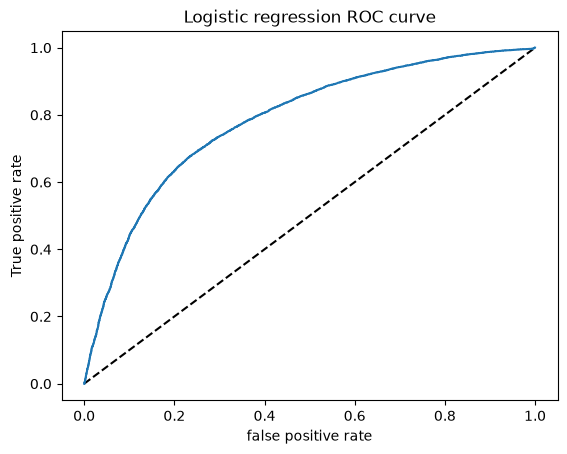

In [11]:
#predicting probabilities

y_pred_probs = pipeline.predict_proba(X_test_scaled)[:,1]

#plotting ROC curve
from sklearn.metrics import roc_curve
fpr,tpr,thresholds = roc_curve(y_test, y_pred_probs)
plt.plot([0,1] , [0,1], 'k--')
plt.plot(fpr, tpr)
plt.xlabel("false positive rate")
plt.ylabel("True positive rate")
plt.title('Logistic regression ROC curve')
plt.show()

In [12]:
#calculating ROCAUC in scikit learn
from sklearn.metrics import roc_auc_score
log_reg = roc_auc_score(y_test, y_pred_probs)
print("logistic regression auc score:" , log_reg)

logistic regression auc score: 0.7836121561001144


In [13]:
# Import necessary libraries
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

# Initialize the Random Forest Classifier with desired parameters
rf = RandomForestClassifier(n_estimators=100, min_samples_leaf=0.12, random_state=21)

# Fit the classifier on the training data
rf.fit(X_train, y_train)

# Make predictions on the test data
y_pred = rf.predict(X_test)

# Calculate and print the accuracy score
rf_accuracy = accuracy_score(y_test, y_pred)
print("Random Forest accuracy score:", rf_accuracy)

# Calculate and print the recall score on the test data
rf_recall = recall_score(y_test, y_pred)
print("recall score:", rf_recall)

# Calculate and print the f1 score on the test data
rf_f1 = f1_score(y_test, y_pred)
print("f1 score :", rf_f1)

# Calculate and print the precision score on the test data
rf_precision = precision_score(y_test, y_pred)
print("Precision score:", rf_precision)

Random Forest accuracy score: 0.7148095238095238
recall score: 0.6407470935772822
f1 score : 0.6918763183618871
Precision score: 0.7518729732751873


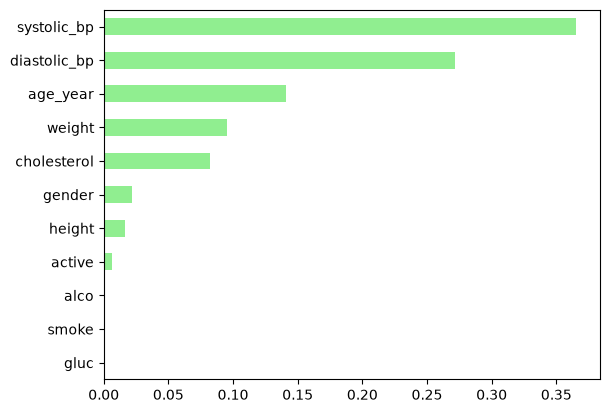

In [14]:
#features importances in sklearn

#create a pd.series of features importance
importances_rf = pd.Series(rf.feature_importances_, index=X_dt.columns)
sorted_importances_rf = importances_rf.sort_values()

#barplot
sorted_importances_rf.plot(kind='barh', color='lightgreen')
plt.show()

In [15]:
#predicting probabilities

y_pred_probs = rf.predict_proba(X_test)[:,1]

#calculating ROCAUC in scikit learn
from sklearn.metrics import roc_auc_score
rf_auc = roc_auc_score(y_test, y_pred_probs)
print('random forest auc score:', rf_auc)

random forest auc score: 0.7796844405318809


In [16]:
from sklearn.metrics import roc_curve
fpr,tpr,thresholds = roc_curve(y_test, y_pred_probs)
rf_fpr = fpr
rf_tpr = tpr

print(rf_fpr, rf_tpr)

[0.00000000e+00 3.80734818e-04 4.75918523e-04 ... 9.96668570e-01
 9.98667428e-01 1.00000000e+00] [0.         0.00152468 0.00190585 ... 0.99971412 0.99990471 1.        ]


In [17]:
from sklearn.ensemble import GradientBoostingClassifier

gbt = GradientBoostingClassifier(n_estimators=100, max_depth=1, random_state=21)
gbt.fit(X_train, y_train)
y_pred = gbt.predict(X_test)

# Calculate and print the accuracy score
gbt_accuracy = accuracy_score(y_test, y_pred)
print("GradientBoosting accuracy score:", gbt_accuracy)

# Calculate and print the recall score on the test data
gbt_recall = recall_score(y_test, y_pred)
print("recall score:", gbt_recall)

# Calculate and print the f1 score on the test data
gbt_f1 = f1_score(y_test, y_pred)
print("f1 score on:", gbt_f1)

# Calculate and print the precision score on the test data
gbt_precision = precision_score(y_test, y_pred)
print("Precision score:", gbt_precision)

GradientBoosting accuracy score: 0.7272380952380952
recall score: 0.6483704974271012
f1 score on: 0.7037649979313199
Precision score: 0.7695091608233431


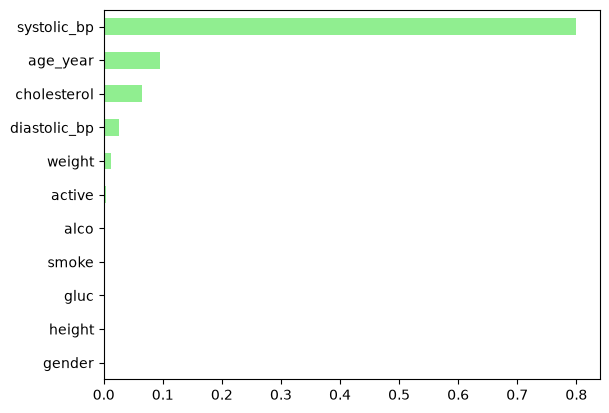

In [18]:
#features importances in sklearn

#create a pd.series of features importance
importances_gbt = pd.Series(gbt.feature_importances_, index=X_dt.columns)
sorted_importances_gbt = importances_gbt.sort_values()

#barplot
sorted_importances_gbt.plot(kind='barh', color='lightgreen')
plt.show()

In [19]:
#predicting probabilities

y_pred_probs = gbt.predict_proba(X_test)[:,1]

#calculating ROCAUC in scikit learn
from sklearn.metrics import roc_auc_score
gbt_auc = roc_auc_score(y_test, y_pred_probs)
print('gbt_auc_score :', gbt_auc)

gbt_auc_score : 0.7963984006380265


In [20]:
from sklearn import svm
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score


In [21]:
from sklearn.svm import SVC

# Fit your SVM classifier with probability=False
svm_classifier = SVC(probability=False)
svm_classifier.fit(X_train, y_train)

# Get decision scores instead of probabilities
y_decision_scores = svm_classifier.decision_function(X_test)

# Calculate ROC AUC score
from sklearn.metrics import roc_auc_score
svm_auc = roc_auc_score(y_test, y_decision_scores)
print('svm_auc_score: ', svm_auc)

# Make predictions on the test data
y_pred = svm_classifier.predict(X_test)

# Calculate and print the accuracy score
svm_accuracy = accuracy_score(y_test, y_pred)
print("SVM accuracy score:", svm_accuracy)

# Calculate and print the recall score on the test data
svm_recall = recall_score(y_test, y_pred)
print("recall score:", svm_recall)

# Calculate and print the f1 score on the test data
svm_f1 = f1_score(y_test, y_pred)
print("f1 score on:", svm_f1)

# Calculate and print the precision score on the test data
svm_precision = precision_score(y_test, y_pred)
print("Precision score:", svm_precision)

svm_auc_score:  0.7858993586610151
SVM accuracy score: 0.7228095238095238
recall score: 0.6234991423670669
f1 score on: 0.6921246099328291
Precision score: 0.777724949482943


In [22]:
#features importances in sklearn
from sklearn.svm import LinearSVC

# Scale the data, then fit a fast linear SVM (hinge loss is the standard SVM setting)
svm_linear = Pipeline([('scaler', StandardScaler()), ('svm', LinearSVC(C=1, loss='hinge', max_iter=5000, random_state=21))])
svm_linear.fit(X_train, y_train)

# Make predictions on the test data
y_pred = svm_linear.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
print("SVM accuracy score:", accuracy)

# The size of each coefficient shows how much the feature matters
feature_importances = pd.Series(np.abs(svm_linear.named_steps['svm'].coef_[0]), index=X_dt.columns).sort_values()
print(feature_importances)

SVM accuracy score: 0.7249047619047619
gender          0.007088
diastolic_bp    0.010798
smoke           0.018360
alco            0.032001
gluc            0.054614
active          0.085056
height          0.085871
weight          0.197975
age_year        0.267896
cholesterol     0.395010
systolic_bp     5.728175
dtype: float64


/opt/anaconda3/lib/python3.13/site-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


In [23]:
# Convert the coefficients to a NumPy array (same column order as X_dt)
result_array = np.abs(svm_linear.named_steps['svm'].coef_[0])

print(type(result_array))

<class 'numpy.ndarray'>


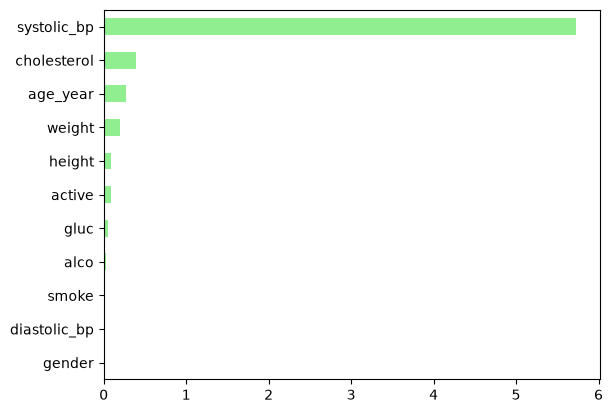

In [24]:
#features importances in sklearn

#create a pd.series of features importance
importances_rf = pd.Series(result_array, index=X_dt.columns)
sorted_importances = importances_rf.sort_values()

#barplot
sorted_importances.plot(kind='barh', color='lightgreen')
plt.show()

In [25]:
from sklearn import svm
from sklearn.svm import SVC
from sklearn.ensemble import VotingClassifier

#instantiate the individual classifiers
steps = [('scaler', StandardScaler()), ('log', LogisticRegression())]
pipeline = Pipeline(steps)
#lr = LogisticRegression(random_state=21)
rf = RandomForestClassifier(n_estimators=100, min_samples_leaf=0.12, random_state=21)
gbt = GradientBoostingClassifier(n_estimators=100, max_depth=1, random_state=21)
svm = SVC(probability=False)

#define a list called classifier containing tuples
classifiers = [('Logistic Regression', pipeline), ('RandomForest classifier', rf), ('gradientboosting clf', gbt), ('Support vector machine', svm)]

#iterate over the defined list of tuples containing the classifier
for clf_name, clf in classifiers:
    clf.fit(X_train, y_train)
    y_pred = clf.predict(X_test)
    print(clf_name, accuracy_score(y_test, y_pred))

Logistic Regression 0.721047619047619
RandomForest classifier 0.7148095238095238
gradientboosting clf 0.7272380952380952
Support vector machine 0.7228095238095238


In [26]:
#instantiate a voting classifer
vc = VotingClassifier(estimators=classifiers)

#fit vc to the training and test and data
vc.fit(X_train, y_train)
y_pred = vc.predict(X_test)

#evaluate the test data accuracy of vc
vc_accuracy = accuracy_score(y_test, y_pred)
print('Voting classifier accuracy:', vc_accuracy)

# Calculate and print the recall score on the test data
vc_recall = recall_score(y_test, y_pred)
print("recall score:", vc_recall)

#Calculate and print the f1 score on the test data
vc_f1 = f1_score(y_test, y_pred)
print("f1 score on:", vc_f1)

#Calculate and print the precision score on the test data
vc_precision = precision_score(y_test, y_pred)
print("Precision score:", vc_precision)

Voting classifier accuracy: 0.7218571428571429
recall score: 0.614446350295407
f1 score on: 0.6882638629449752
Precision score: 0.7822394759189616


In [27]:
# Calculate the combined feature importances (each model rescaled to add up to 1, so they count equally)
svm_share = result_array / result_array.sum()
combined_feature_importances = np.average([rf.feature_importances_, gbt.feature_importances_, svm_share], axis=0)

# Print the combined feature importances with their names, highest first
print("Combined Feature Importances:")
print(pd.Series(combined_feature_importances, index=X_dt.columns).sort_values(ascending=False))

Combined Feature Importances:
systolic_bp     0.665704
diastolic_bp    0.099509
age_year        0.091630
cholesterol     0.067930
weight          0.045212
height          0.009693
gender          0.007635
active          0.007475
gluc            0.002645
alco            0.001676
smoke           0.000889
dtype: float64


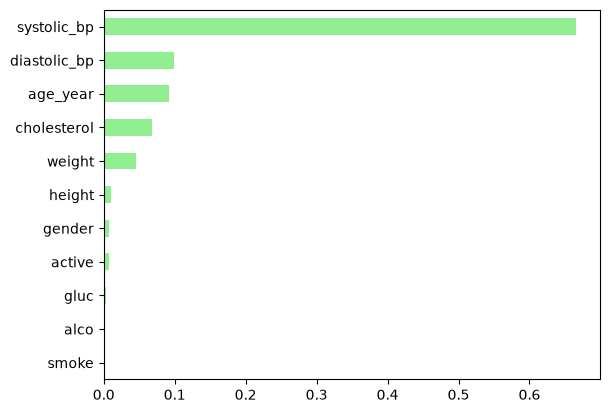

In [28]:
#features importances in sklearn

#create a pd.series of features importance
importances_rf = pd.Series(combined_feature_importances, index=X_dt.columns)
sorted_importances = importances_rf.sort_values()

#barplot
sorted_importances.plot(kind='barh', color='lightgreen')
plt.savefig('combined_feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()

In [29]:
#predicting on xtest

y_pred = vc.predict(X_test)

#calculating ROCAUC in scikit learn
from sklearn.metrics import roc_auc_score
vc_auc = roc_auc_score(y_test, y_pred)
print('vc_auc_score :', vc_auc)

vc_auc_score : 0.7217958003142749


In [30]:
test_metrics = pd.DataFrame({
    'model':['Logistic_regression','RandomForest Classifier','GradientBoosting Classifier','SVM Classifier','Ensemble Voting Classifier'],
    'accuracy':[lr_accuracy,rf_accuracy,gbt_accuracy,svm_accuracy,vc_accuracy],
    'precision':[lr_precision,rf_precision,gbt_precision,svm_precision,vc_precision],
    'recall':[lr_recall,rf_recall,gbt_recall,svm_recall,vc_recall],
    'f1':[lr_f1,rf_f1,gbt_f1,svm_f1,vc_f1],
    'Auc score':[log_reg,rf_auc,gbt_auc,svm_auc,vc_auc]
})

test_metrics.transpose().reset_index().rename(columns={'index':'metrics'})

,metrics,0,1,2,3,4
0,model,Logistic_regression,RandomForest Classifier,GradientBoosting Classifier,SVM Classifier,Ensemble Voting Classifier
1,accuracy,0.721048,0.71481,0.727238,0.72281,0.721857
2,precision,0.741761,0.751873,0.769509,0.777725,0.782239
3,recall,0.677721,0.640747,0.64837,0.623499,0.614446
4,f1,0.708296,0.691876,0.703765,0.692125,0.688264
5,Auc score,0.783612,0.779684,0.796398,0.785899,0.721796


In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score

# The svm model is already trained in the voting classifier cell, so we use its decision scores
# (they give the same ROC curve as probabilities, without retraining)

# Calculate ROC curve and ROC AUC for each model
fpr1, tpr1, _ = roc_curve(y_test, pipeline.predict_proba(X_test)[:, 1])
roc_auc1 = roc_auc_score(y_test, pipeline.predict_proba(X_test)[:, 1])

fpr2, tpr2, _ = roc_curve(y_test, rf.predict_proba(X_test)[:, 1])
roc_auc2 = roc_auc_score(y_test, rf.predict_proba(X_test)[:, 1])

fpr3, tpr3, _ = roc_curve(y_test, gbt.predict_proba(X_test)[:, 1])
roc_auc3 = roc_auc_score(y_test, gbt.predict_proba(X_test)[:, 1])

fpr4, tpr4, _ = roc_curve(y_test, svm.decision_function(X_test))
roc_auc4 = roc_auc_score(y_test, svm.decision_function(X_test))

fpr5, tpr5, _ = roc_curve(y_test, vc.predict(X_test))
roc_auc5 = roc_auc_score(y_test, vc.predict(X_test))


# Plot ROC curves
plt.figure(figsize=(8, 6))
plt.plot(fpr1, tpr1, color='b', lw=2, label=f'Logistic Regression (AUC = {roc_auc1:.2f})')
plt.plot(fpr2, tpr2, color='g', lw=2, label=f'Random Forest (AUC = {roc_auc2:.2f})')
plt.plot(fpr3, tpr3, color='r', lw=2, label=f'Gradient Boosting (AUC = {roc_auc3:.2f})')
plt.plot(fpr4, tpr4, color='k', lw=2, label=f'SVM (AUC = {roc_auc4:.2f})')
plt.plot(fpr5, tpr5, color='c', lw=2, label=f'Voting Classifier (AUC = {roc_auc5:.2f})')

plt.plot([0, 1], [0, 1], color='gray', linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves')
plt.legend(loc='lower right')
plt.savefig('roc_curves.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
#Clinical plausibility audit: flag blood pressure, height, and weight readings that are physically impossible
bmi = dt['weight'] / (dt['height'] / 100) ** 2

checks = {
    'Systolic outside 70 to 250 mmHg': (dt['systolic_bp'] < 70) | (dt['systolic_bp'] > 250),
    'Diastolic outside 40 to 150 mmHg': (dt['diastolic_bp'] < 40) | (dt['diastolic_bp'] > 150),
    'Diastolic equal to or higher than systolic': dt['diastolic_bp'] >= dt['systolic_bp'],
    'Height under 120 cm': dt['height'] < 120,
    'Weight under 30 kg': dt['weight'] < 30,
    'BMI under 13 or over 60': (bmi < 13) | (bmi > 60)
}
for name, flag in checks.items():
    print(f'{name}: {flag.sum():,}')

implausible = pd.concat(checks, axis=1).any(axis=1)
print(f'\nRecords failing at least one check: {implausible.sum():,} ({implausible.mean():.1%})')
print('Highest systolic reading:', dt['systolic_bp'].max(), '| Highest diastolic reading:', dt['diastolic_bp'].max())

In [ ]:
#Retrain on clean records only: do impossible readings affect linear models and tree models differently?
X_clean = X_dt[~implausible].values
y_clean = dt.loc[~implausible, 'cardio'].values
Xc_train, Xc_test, yc_train, yc_test = train_test_split(X_clean, y_clean, test_size=0.3, random_state=21, stratify=y_clean)

clean_results = []
for name, model in [('Logistic Regression', Pipeline([('scaler', StandardScaler()), ('log', LogisticRegression())])),
                    ('Gradient Boosting', GradientBoostingClassifier(n_estimators=100, max_depth=1, random_state=21))]:
    for data_name, (Xa, ya, Xb, yb) in [('All records', (X_train, y_train, X_test, y_test)),
                                        ('Clean records', (Xc_train, yc_train, Xc_test, yc_test))]:
        model.fit(Xa, ya)
        probs = model.predict_proba(Xb)[:, 1]
        clean_results.append([name, data_name, accuracy_score(yb, probs >= 0.5), roc_auc_score(yb, probs)])

print(pd.DataFrame(clean_results, columns=['Model', 'Data', 'Accuracy', 'AUC']).round(3))

#the linear SVM coefficient for systolic blood pressure, before and after cleaning
svm_clean = Pipeline([('scaler', StandardScaler()), ('svm', LinearSVC(C=1, loss='hinge', max_iter=5000, random_state=21))])
svm_clean.fit(Xc_train, yc_train)
clean_coefs = pd.Series(np.abs(svm_clean.named_steps['svm'].coef_[0]), index=X_dt.columns)
print('\nSystolic coefficient, all records:', round(result_array[list(X_dt.columns).index('systolic_bp')], 2))
print('Systolic coefficient, clean records:', round(clean_coefs['systolic_bp'], 2))

In [ ]:
#Tuning the tree models: the original settings kept the trees very small
tuned_models = {
    'Random Forest (original: min_samples_leaf=0.12)': rf,
    'Random Forest (tuned: min_samples_leaf=50, 200 trees)': RandomForestClassifier(n_estimators=200, min_samples_leaf=50, random_state=21, n_jobs=-1),
    'Gradient Boosting (original: max_depth=1)': gbt,
    'Gradient Boosting (tuned: max_depth=3, 200 trees)': GradientBoostingClassifier(n_estimators=200, max_depth=3, random_state=21)
}

tuning_results = []
for name, model in tuned_models.items():
    model.fit(X_train, y_train)
    probs = model.predict_proba(X_test)[:, 1]
    tuning_results.append([name, accuracy_score(y_test, probs >= 0.5), recall_score(y_test, probs >= 0.5), roc_auc_score(y_test, probs)])

tuning_df = pd.DataFrame(tuning_results, columns=['Model', 'Accuracy', 'Recall', 'AUC']).round(3)
tuning_df

In [ ]:
#A single classification tree with 3 questions, and a one-question clinical rule
from sklearn.tree import DecisionTreeClassifier, plot_tree

single_tree = DecisionTreeClassifier(max_depth=3, random_state=21)
single_tree.fit(X_train, y_train)
tree_probs = single_tree.predict_proba(X_test)[:, 1]
print('Single tree (3 questions): accuracy', round(accuracy_score(y_test, tree_probs >= 0.5), 3), '| AUC', round(roc_auc_score(y_test, tree_probs), 3))

#clinical rule: systolic 130 or higher (ACC/AHA stage 1 hypertension) means predict CVD
systolic_col = list(X_dt.columns).index('systolic_bp')
rule_pred = (X_test[:, systolic_col] >= 130).astype(int)
print('Rule, systolic 130 or higher: accuracy', round(accuracy_score(y_test, rule_pred), 3), '| recall', round(recall_score(y_test, rule_pred), 3))

plt.figure(figsize=(18, 8))
plot_tree(single_tree, feature_names=list(X_dt.columns), class_names=['No CVD', 'CVD'], filled=True, rounded=True, fontsize=10)
plt.title('Single Classification Tree (3 Questions)')
plt.savefig('single_classification_tree.png', dpi=150, bbox_inches='tight')
plt.savefig('single_classification_tree.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
#Soft voting: average the predicted probabilities instead of counting yes/no votes, so AUC can be measured properly
soft_vc = VotingClassifier(estimators=[('Logistic Regression', Pipeline([('scaler', StandardScaler()), ('log', LogisticRegression())])),
                                       ('RandomForest classifier', RandomForestClassifier(n_estimators=100, min_samples_leaf=0.12, random_state=21)),
                                       ('gradientboosting clf', GradientBoostingClassifier(n_estimators=100, max_depth=1, random_state=21))],
                           voting='soft')
soft_vc.fit(X_train, y_train)
soft_probs = soft_vc.predict_proba(X_test)[:, 1]

print('Hard voting (original): accuracy', round(vc_accuracy, 3), '| AUC', round(vc_auc, 3))
print('Soft voting:            accuracy', round(accuracy_score(y_test, soft_probs >= 0.5), 3), '| AUC', round(roc_auc_score(y_test, soft_probs), 3))